In [1]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc

In [ ]:
1. Построить график функции y1−α+β − yβ для β ∈ (0, α), где yt – квантиль распределения

In [ ]:
(a) N(0, 1)

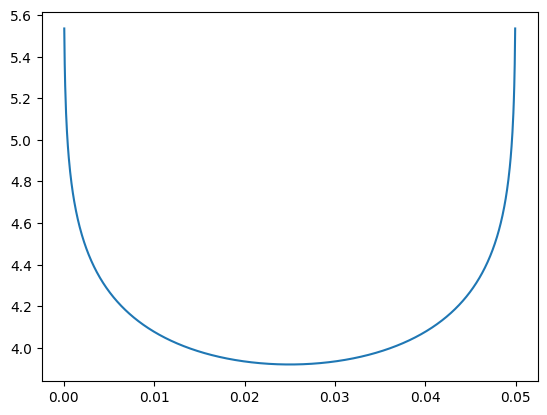

In [2]:
alpha = 0.05
l = np.linspace(0, alpha, 1000)
graph = [sc.stats.norm.ppf(1-alpha + beta, loc = 0, scale = 1) - sc.stats.norm.ppf(beta, loc = 0, scale = 1)  for beta in l]
plt.plot(l, graph)
plt.show()

In [ ]:
(b) Gamma(n, 1), n = [1, 2, 5, 10, 100]

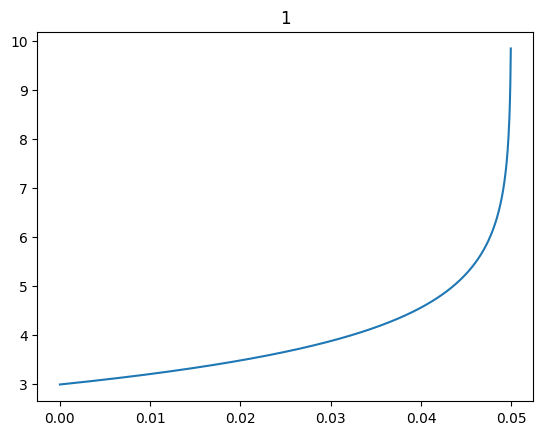

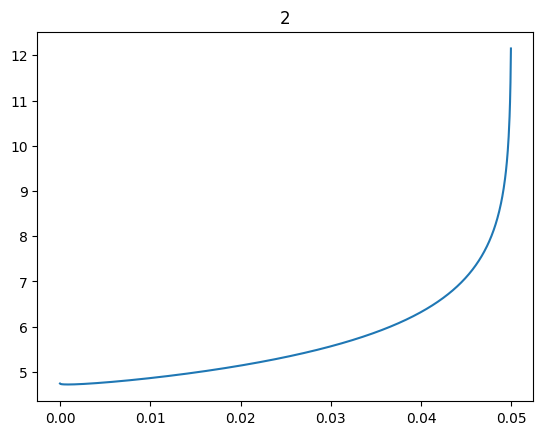

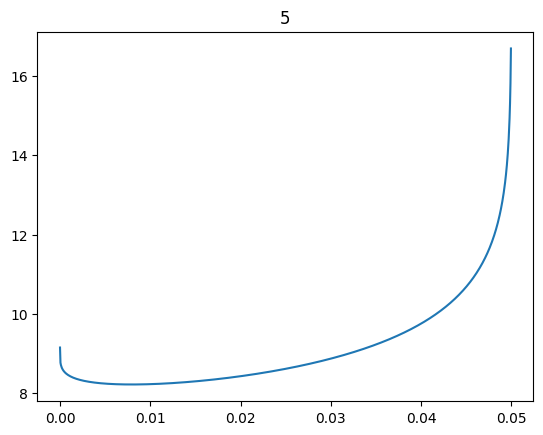

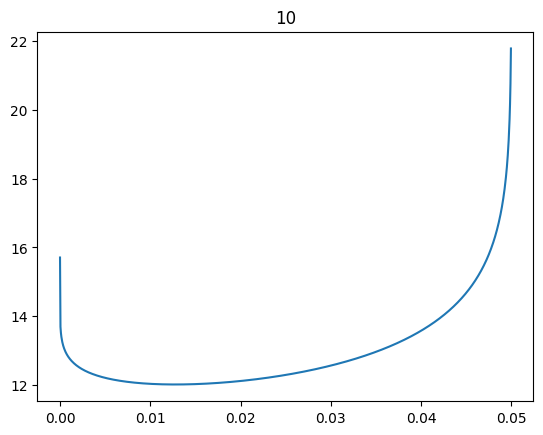

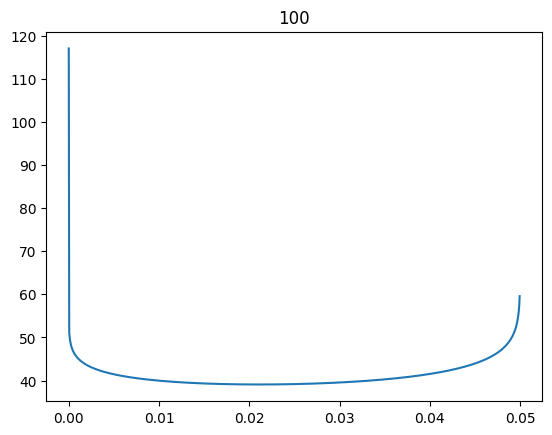

In [3]:
numbers = [1, 2, 5, 10, 100]
alpha = 0.05
l = np.linspace(0, alpha, 1000)
for n in numbers:
    graph = [sc.stats.gamma.ppf(1-alpha + beta, n, 1) - sc.stats.gamma.ppf(beta, n, 1)  for beta in l]
    plt.plot(l, graph)
    plt.title(n)
    plt.show()

In [ ]:
(c) R[0, 1]

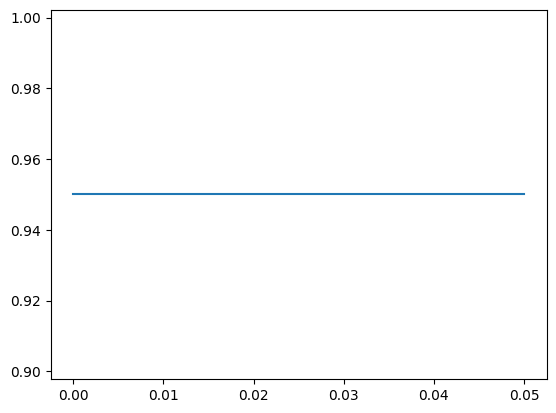

In [12]:
alpha = 0.05
l = np.linspace(0, alpha, 1000)
graph = [sc.stats.uniform.ppf(1-alpha + beta, 0, 1) - sc.stats.uniform.ppf(beta, 0, 1)  for beta in l]
plt.plot(l, graph)
plt.show()

In [ ]:
(d) Beta(a, b), a = b = 5, a = 10, b = 2, a = 20, b = 1.

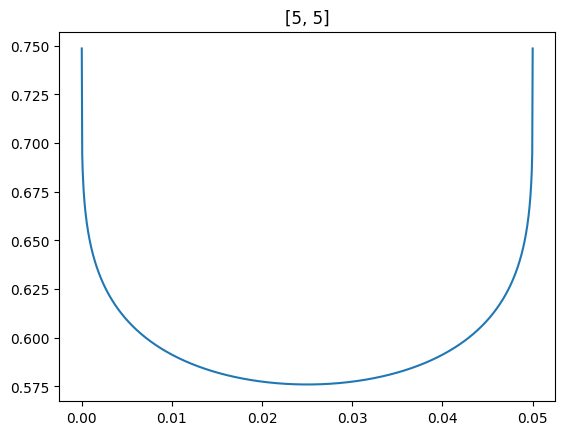

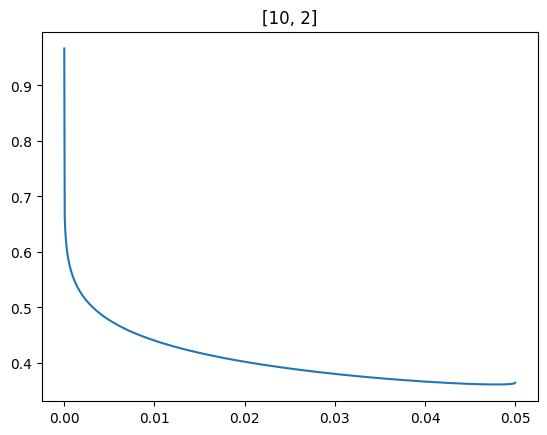

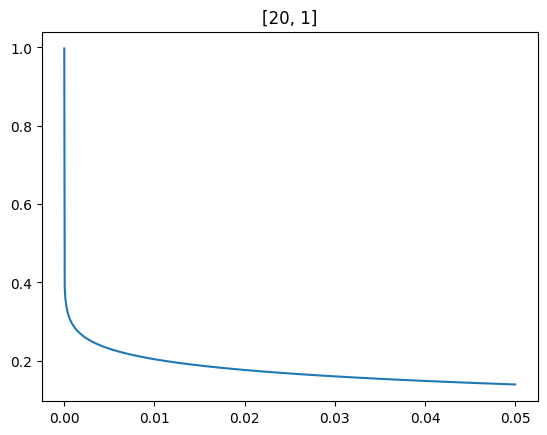

In [2]:
params = [[5,5], [10,2], [20,1]]
alpha = 0.05
l = np.linspace(0, alpha, 1000)
for tetta in params:
    graph = [sc.stats.beta.ppf(1-alpha + beta, tetta[0], tetta[1]) - sc.stats.beta.ppf(beta, tetta[0], tetta[1])  for beta in l]
    plt.plot(l, graph)
    plt.title(tetta)
    plt.show()

In [ ]:
2. X1, ..., Xn ∼ R[0, θ].

In [ ]:
(a) Построить асимптотический доверительный интервал, используя X. Найти эмпирически до-
верительную вероятность этого интервала (построить 1000 выборок, подсчитать долю тех,
для которых интервал накрыл истинное значение параметра, для n = 20, 50, 100.)

(b) Построить точный доверительный интервал, используя достаточную статистику. Сравнить
средние длины точного и асимптотического интервалов при n = 20, 50, 100.

In [4]:
numbers = [20,50,100]
tetta = 8
alpha = 0.05
for n in numbers:
    freq1 = 0
    freq2 = 0
    range1=0
    range2=0
    for j in range(1000):
        data = np.random.uniform(0,tetta, size = n)
        b = 2*np.mean(data) - 2*np.max(data)*sc.stats.norm.ppf(alpha/2, loc = 0, scale = 1)/np.sqrt(12*n)
        a = 2*np.mean(data) - 2*np.max(data)*sc.stats.norm.ppf(1-alpha/2, loc = 0, scale = 1)/np.sqrt(12*n)
        if tetta<b and  tetta>a:
            freq1+=1/1000
        range1+=(b-a)/1000

        b = np.max(data)/alpha**(1/n)
        a = np.max(data)
        if tetta<b and tetta> a:
            freq2+=1/1000
        range2+=(b-a)/1000
        
    print(n, freq1, freq2, range1, range2)

20 0.9490000000000007 0.9570000000000007 3.862385369209084 1.233268990946146
50 0.9480000000000007 0.9500000000000007 2.5103626376980746 0.48429753241530266
100 0.9540000000000007 0.9420000000000007 1.7921308894726333 0.2408111845071359


In [ ]:
X1, ..., Xn ∼ Bern(θ). а) Построить асимптотический доверительный интервал двумя способами
с помощью X, сравнить средние длины полученных интервалов (генерировать 1000 выборок, по
каждой строить оба интервала, посчитать и показать средние длины) для θ = 0.1, 0.4, 0.5, 0.9 и
n = 20, 50, 100.

In [4]:
numbers = [20,50,100]
tetta = 0.1
alpha = 0.05
for n in numbers:
    freq1 = 0
    freq2 = 0
    range1=0
    range2=0
    for j in range(1000):
        data = np.random.binomial(1, tetta, size = n)
        m = np.mean(data)
        quan1= sc.stats.norm.ppf(alpha/2, loc = 0, scale = 1)
        quan2= sc.stats.norm.ppf(1-alpha/2, loc = 0, scale = 1)
        b = m - np.sqrt(m*(1-m)/n)*quan1
        a =  m - np.sqrt(m*(1-m)/n)*quan2
        if a<0:
            a=0
        if tetta<b and  tetta>a:
            freq1+=1/1000
        range1+=(b-a)/1000

        bred=np.arcsin(np.sqrt(m))
        b = (np.sin(bred-quan1/(2*np.sqrt(n))))**2
        a = (np.sin(bred-quan2/(2*np.sqrt(n))))**2
        if np.sin(bred-quan2/(2*np.sqrt(n)))<0:
            a=0
        if tetta<b and tetta>a:
            freq2+=1/1000
        range2+=(b-a)/1000
    print(n, freq1, freq2, range1, range2)

20 0.8740000000000007 0.8700000000000007 0.21317008113996344 0.23350475222962846
50 0.8760000000000007 0.9450000000000007 0.1572420239881137 0.15783756686883238
100 0.9290000000000007 0.9530000000000007 0.11595910871348596 0.11525337228068647


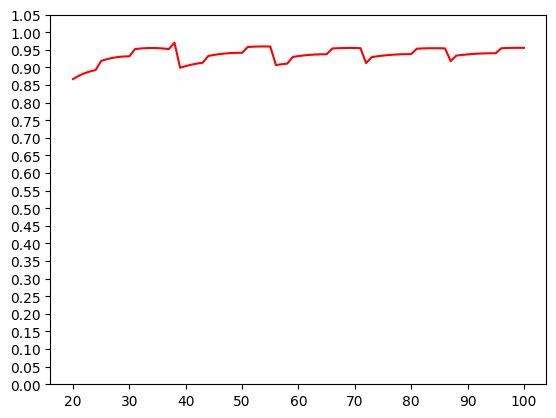

In [9]:
l = np.arange(20,101,1)
graph = []
for n in range (20,101):
    t1 = n*( np.sin(quan2/(2*np.sqrt(n)) + np.arcsin(np.sqrt(tetta))) )**2
    t2 = n*( np.sin(quan1/(2*np.sqrt(n)) + np.arcsin(np.sqrt(tetta))) )**2
    exact_confidence = sc.stats.binom.cdf(t1, n, tetta) - sc.stats.binom.pmf(t1,n,tetta) - sc.stats.binom.cdf(t2, n, tetta)
    graph.append(exact_confidence)
plt.plot(l, graph, color = "red")
plt.yticks(np.arange(0, 1.1, 0.05))
plt.show()

In [ ]:
4. * X1, ..., Xn ∼ Gamma(θ, 1). Построить асимптотический доверительный интервал для θ на основе
ОМП.

In [4]:
def lnlh(tetta, data, n):
    ans = -n*np.log(sc.special.gamma(tetta))
    for k in range(n):
        ans += (tetta-1)*np.log(data[k]) - data[k]
    return(ans)
    
numbers = [20,50,100]
tetta = 8
alpha = 0.05
quan1=sc.stats.norm.ppf(1-alpha/2, 0, 1)
quan2=sc.stats.norm.ppf(alpha/2, 0, 1)
for n in numbers:
    freq=0
    for k in range(100):
        data = np.random.gamma(tetta,1, size=n)
        mle = sc.optimize.minimize(lambda x: -lnlh(x, data, n), x0=np.mean(data), method='BFGS').x[0]
        inf = sc.special.polygamma(1, mle) 
        if tetta>mle-quan1/np.sqrt(n*inf) and  tetta < mle-quan2/np.sqrt(n*inf):
            freq+=1/100
    print(n,freq)

20 0.9600000000000006
50 0.9500000000000006
100 0.9600000000000006
